# 02 · Feature engineering

**Indoor Location Prediction Using Wi-Fi Signals** (Project 9) · Team T084

What our models see: the RSSI values, three signal statistics and AP-affinity (our own feature),
and a check of which of them help.

## 1. Three feature sets

**What:** clean the training file as in notebook 01 and fit one FeatureBuilder per feature set on
the cleaned training scans.

**Why:** features may learn only from training scans; the test set (the UCI file
validationData.csv) is only transformed.

**Result:** rssi has 464 columns (the WAPs heard in training), rssi+stats 467 and
rssi+stats+affinity 475.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from indoorloc import config, data, features, plots

plt.rcParams["figure.dpi"] = 150  # larger figures in the notebook
train, _ = data.clean_training(data.load_csv(config.TRAIN_CSV))
test = data.load_csv(config.TEST_CSV)
X, y = train[config.WAP_COLS], train[config.TARGET_COLS]
builders = {name: features.FeatureBuilder(name).fit(X, y) for name in config.FEATURE_SETS}
for name, builder in builders.items():
    print(f"{name}: {builder.transform(test).shape[1]} columns")

rssi: 464 columns
rssi+stats: 467 columns
rssi+stats+affinity: 475 columns


**Missing values and scaling.** "Not heard" is -110 dBm, below every real reading. We add no
separate heard/not-heard column per WAP: for a tree, a split below -105 dBm already means "not
heard", and `n_heard` counts the heard WAPs. We do not scale the RSSI: trees use only the order of
the values, and all RSSI columns share one unit (dBm), so kNN treats them alike. Nothing is fitted
on the test set. Scaling (fitted on training data only) is needed in Phase 2, for the neural network.

## 2. Signal statistics

**What:** three numbers per scan: n_heard (WAPs heard), max_rssi (strongest reading) and mean_rssi
(mean of the heard readings).

**Why:** a short summary of how many WAPs are around and how near the closest one is.

**Result:** the first three training scans hear 17, 16 and 15 WAPs, with strongest readings of
-53, -46 and -61 dBm.

In [2]:
builders["rssi+stats"].transform(train.head(3))[["n_heard", "max_rssi", "mean_rssi"]].round(1)

,n_heard,max_rssi,mean_rssi
0,17,-53.0,-77.6
1,16,-46.0,-76.6
2,15,-61.0,-82.9


## 3. AP-affinity: where does each WAP "live"?

**What:** each WAP heard in at least 5 training scans gets a profile (building shares, mean floor,
location), averaged over the training scans that hear it with the weight ((rssi - min) / -min)^e,
where min = -105 dBm (1 dB below the weakest training reading), so stronger readings count more.

**Why:** a WAP is fixed on one floor of one building, so the scans that hear it show where it is.

**Result:** 414 WAPs get a profile; the most heard one, WAP502 (4,269 scans), is heard only in
building 2 (aff_b2 = 1.00), with a mean floor of 1.83.

In [3]:
affinity = builders["rssi+stats+affinity"].affinity_  # learned from training scans only
n_scans = (train[affinity.waps_] > config.FILL_VALUE).sum()  # training scans that hear each WAP
wap = n_scans.idxmax()
print(f"{len(affinity.waps_)} WAPs have a profile; min = {affinity.min_rssi_:.0f} dBm")
print(f"Most heard: {wap}, in {n_scans[wap]:,} training scans")
profile = affinity.profiles_[affinity.waps_.index(wap)]
pd.Series(profile, index=features.AFFINITY_COLS[:6]).round(2).to_frame(wap)

414 WAPs have a profile; min = -105 dBm
Most heard: WAP502, in 4,269 training scans


,WAP502
aff_b0,0.00
aff_b1,0.00
aff_b2,1.00
aff_floor,1.83
aff_lon,-7347.69
aff_lat,4864825.38


## 4. AP-affinity of one test scan

**What:** the 8 AP-affinity columns of one random test scan (the weighted average of the profiles
of the WAPs it hears, then the location of its strongest known WAP) next to its true building,
floor and position.

**Why:** this is the hint AP-affinity gives the models.

**Result:** it points to building 1 (aff_b1 = 1.0) and floor 1.05 for a scan truly on building 1,
floor 1, and its location is 12.06 m from the true one (Web-Mercator meters; one such meter is
about 0.77 m on the ground): a strong hint, not yet the answer.

In [4]:
scan = test.sample(1, random_state=config.SEED)  # one test scan, picked at random
columns = builders["rssi+stats+affinity"].transform(scan)[features.AFFINITY_COLS]
gap = np.hypot(columns["aff_lon"] - scan["LONGITUDE"], columns["aff_lat"] - scan["LATITUDE"])
print(f"AP-affinity location is {gap.iloc[0]:.2f} m from the true position")
pd.concat([columns, scan[config.TARGET_COLS]], axis=1).round(2)

AP-affinity location is 12.06 m from the true position


,aff_b0,aff_b1,aff_b2,aff_floor,aff_lon,aff_lat,aff_top_lon,aff_top_lat,BUILDINGID,FLOOR,LONGITUDE,LATITUDE
436,0.0,1.0,0.0,1.05,-7533.67,4864930.11,-7533.55,4864931.25,1,1,-7538.57,4864919.09


## 5. Feature check: which blocks help?

**What:** the Baseline RF settings (300 trees, default settings) on each feature set, scored with
5-fold user-group cross-validation (CV) on the training data; the error bars show the spread over
the folds.

**Why:** to see whether a block adds information that carries over to new users and phones.

**Result:** the signal statistics did not help: floor accuracy fell from 78.5% to 78.0% and the
mean 2D error rose from 15.55 m to 15.87 m. AP-affinity helped, above all for position: 80.6% and
11.38 m. (2D error = straight-line distance between predicted and true position.)

,feature_set,building_acc,building_acc_std,floor_acc,floor_acc_std,mean_2d,mean_2d_std
0,rssi,0.9962,0.0041,0.7849,0.1524,15.5538,4.9232
1,rssi+stats,0.9965,0.0037,0.7799,0.1565,15.8709,4.8976
2,rssi+stats+affinity,0.9966,0.0056,0.8057,0.1483,11.3759,4.1129


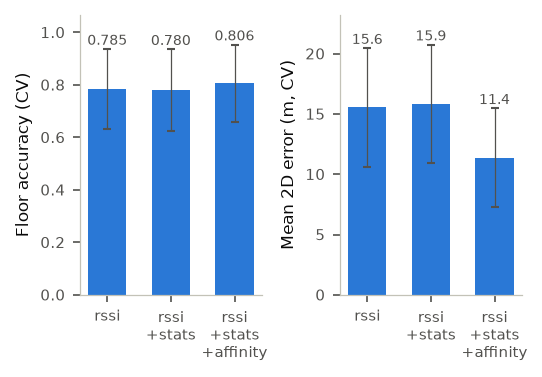

In [5]:
check = pd.read_csv(config.RESULTS_DIR / "metrics" / "feature_check.csv")
fig = plots.feature_check(check)
check

## Summary

- Everything the features need is learned from training scans only: which 464 WAPs to keep and the
  414 WAP profiles behind the 8 AP-affinity columns.
- AP-affinity turns "which WAPs does this scan hear?" into a rough building, floor and location;
  it cut the CV mean 2D error from 15.87 m to 11.38 m.
- The signal statistics did not help (slightly worse in CV); they stay in the full set, which
  scored best.